# KQC AirbridgeCrossings — airbridge crossings and a mechanical airbridge test array (Quantcore PDK rebuild)

**What the chip is.** **Source:** KQCircuits `chips/airbridge_crossings.py` (`AirbridgeCrossings`, default parameters, chip name "CTest"),
© IQM Finland Oy, GPL-3.0 (`other-libs/KQCircuits-main/.../kqcircuits/chips/airbridge_crossings.py`,
<https://github.com/iqm-finland/KQCircuits>). Spec: `docs/designs/kqc/test_chips.md` (row *AirbridgeCrossings*).

A process test chip. On the left a straight line PL-1 (NW → SW) and a line PL-3 (WN → WS) that weaves across it 20
times, each crossing an `AirbridgeConnection` that carries PL-3 over PL-1. On the right the same pair without
crossings: PL-2 straight (NE → SE) and PL-4 weaving between x = 7500 and 8000 µm (EN → ES). In the middle a
mechanical array: 19 bridge lengths × 8 widths × 4 distances = 608 short straight CPWs, with 5 default airbridges
across every second row (rows inside 1000 < y < 9000 µm only): 1280 bridges.

**Kept exactly (same KQC cells, parameters and positions):** the SMA8 launcher assignment
{1: PL-1-IN, 2: PL-2-IN, 3: PL-4-IN, 4: PL-4-OUT, 5: PL-2-OUT, 6: PL-1-OUT, 7: PL-3-OUT, 8: PL-3-IN}; the four
lines as Designer routes with KQC's nodes (`crossings = 10`, step = 4400 / 9.5 / 2 = 231.58 µm, wiggle 250 µm),
the 20 crossings as route waypoints with `airbridge=True` (KQC `Node(..., AirbridgeConnection)`); the 608 CPWs as
`WaveguideCoplanarStraight` cells of KQC's length 2 · 5 · (distance + width) + 4 µm centred on KQC's grid
(3600, 9650) + (400 j, −121 i − 2350 k); the 1280 `AirbridgeRectangular` cells (KQC's default `Airbridge`, no
parameters) at x offsets 50 · (n − 2) µm. KQC's commented-out per-element bridge length / width are not used by
KQC either, so all bridges are identical; only the CPW length varies. Results 1 XORs the chip with a stand-alone KQC build.

**Substituted:** the mechanical-test CPWs are `WaveguideCoplanarStraight` cells (KQC draws each as a two-point
`WaveguideCoplanar`, whose `path` a `design.json` cannot carry, and a route needs a port end). Same gap geometry;
KQC's `WaveguideCoplanar` adds a 5 µm (`margin`) end block to `ground_grid_avoidance` at each term-0 end that the
bare straight cell does not (see the XOR in Results 1; KQC's grid is drawn here, so the grid may come up to 5 µm closer to those stub ends than in KQC).

**This rebuild on the Quantcore PDK** (not a replica; we distribute it under GPL-3.0):

| topic | KQC source | this rebuild (Quantcore PDK) |
|---|---|---|
| die | 10 × 10 mm, KQC `ChipFrame` | same 10 × 10 mm, Quantcore die frame (L dicing markers, 3 × 3 alignment grids, chip boundary, device ID "CTest") |
| launchers | SMA8, `launcher_indent` 800 µm (outer etch 20 µm from the edge) | SMA8, indent **880 µm** from the PDK pad rule (outer etch `frame.pad_edge` = 100 µm, 80 µm further in); same assignment |
| substrate | silicon (KQC simulation default) | sapphire 650 µm, εr 10.25 |
| junctions | none | none |
| cheese | KQC's whole-area ground grid (`with_grid`, in KQC's mask builds) | **the original wins:** KQC's grid (`with_grid=True`), so no PDK band |
| elements, positions, routes | — | kept: KQC's cells, parameters, positions and paths; waypoints from the launcher ports |
| placement | centred | centred (36 µm off in y, inside the 50 µm tolerance: no shift) |

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its
own cell with a picture of the chip so far — the die with its SMA8 launchers, the launchers and the pad rule, the test structures (the mechanical airbridge array), the routing (the four lines, PL-3 crossing PL-1 on 20 airbridges), and then the whole chip (the centring and the save). Then the same steps as the Flow strip of the Quantcore
KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to HFSS, the
component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM against the
LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in a few cells, with its outputs) is kept as `airbridge_crossings.v1.ipynb`; both save the same `airbridge_crossings.json`.

This test chip has no circuit to simulate (through lines only): the LOM and Simulate steps say in one sentence why
not, and the Results step is the comparison with KQC's own build (the XOR); Check and Fab run as in the v1.

## Setup

The imports, the output folders and the switches. `FULL_FAB = False` skips the fab-only corner rounding in
Fab 1 (`qcc mask` writes the complete file). The segment pictures go to `build/snapshots/airbridge_crossings/` (not kept
in the repo), the final snapshots next to the notebook.

`LIVE`: with KLayout open (the default) every change below is pushed to the KLayout window as you run it; with
`QCC_LIVE=0` the notebook builds headless and only writes files. `_common` holds the helpers the design
notebooks share (tables, snapshots, the PDK placement, the FEM and feedback steps).

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

On this chip the FEM switches change nothing (it has no sim groups); they are kept so that every design notebook
starts the same way.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK and FEM step helpers
from quantcore_circuits.designer import Designer
from kqcircuits.pya_resolver import pya

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
FULL_FAB = False                                 # True: also round the corners in the fab export (slow here)
OUT = Path("examples/designs/kqc/test_chips")                 # design JSON + final snapshots
STEPS = Path("build/snapshots/airbridge_crossings")  # step-by-step snapshots (build/ is not kept in the repo)

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

Every rule below comes from the PDK object (`get_pdk()`), not from this notebook: the stack feeds the LOM
estimates and the FEM exports, the frame and pad rule shape the die, the junction rule sizes the junctions,
and the cheese, 3/0 keep-out and corner-rounding rules apply when the mask is written.

This chip has no junctions; it uses the stack, the frame and pad rule, the cheese / 3/0 rules and the fab layer map.

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

# Design: the layout, one segment at a time

The chip is built the way it is laid out by hand: the die and its launchers, the pad check, the test structures,
the lines, and then the whole chip. A process test chip has no qubits, readout or coupling, so those segments are not
here: the test structures take their place. Each segment is one cell with one picture of the chip so far. The array
joins nothing and no line runs to it, so it can come before the lines (the v1 placed the lines first, in one cell:
`save_design` writes the v1's key order back). KQC's ground grid (`with_grid`, ≈ 0.8 M holes) is drawn in every build, so each picture rebuilds the whole chip:
the pictures stay at the v1's size, one per segment.

| segment | what is placed here |
|---|---|
| 1 | the 10 × 10 mm die with the Quantcore frame and the SMA8 holder's eight launchers (KQC's assignment) |
| 2 | the launchers and the pad rule (they come with the die): nothing added, the check and a zoom |
| 3 | the test structures: the mechanical airbridge array (608 short CPWs, 1280 bridges) |
| 4 | the routing: PL-1 and PL-2 straight, PL-3 weaving across PL-1 on 20 airbridge crossings, PL-4 weaving beside PL-2 without crossing |
| 5 | the whole chip: the centring check and the save |

## Design 1 · The die, its frame and the launchers

`Designer(...)` starts the 10 × 10 mm chip with the chip name "CTest" (the device ID) and KQC's SMA8 launcher assignment for this chip (only the assigned pads are drawn). `with_grid=True`
asks for KQC's whole-area ground grid (the original's cheese): the PDK band is then not added. The frame is the PDK
default (L dicing markers 1000/0, 3 × 3 alignment grids 1001/0, boundary 100/0); KQC's own `ChipFrame` is not drawn.

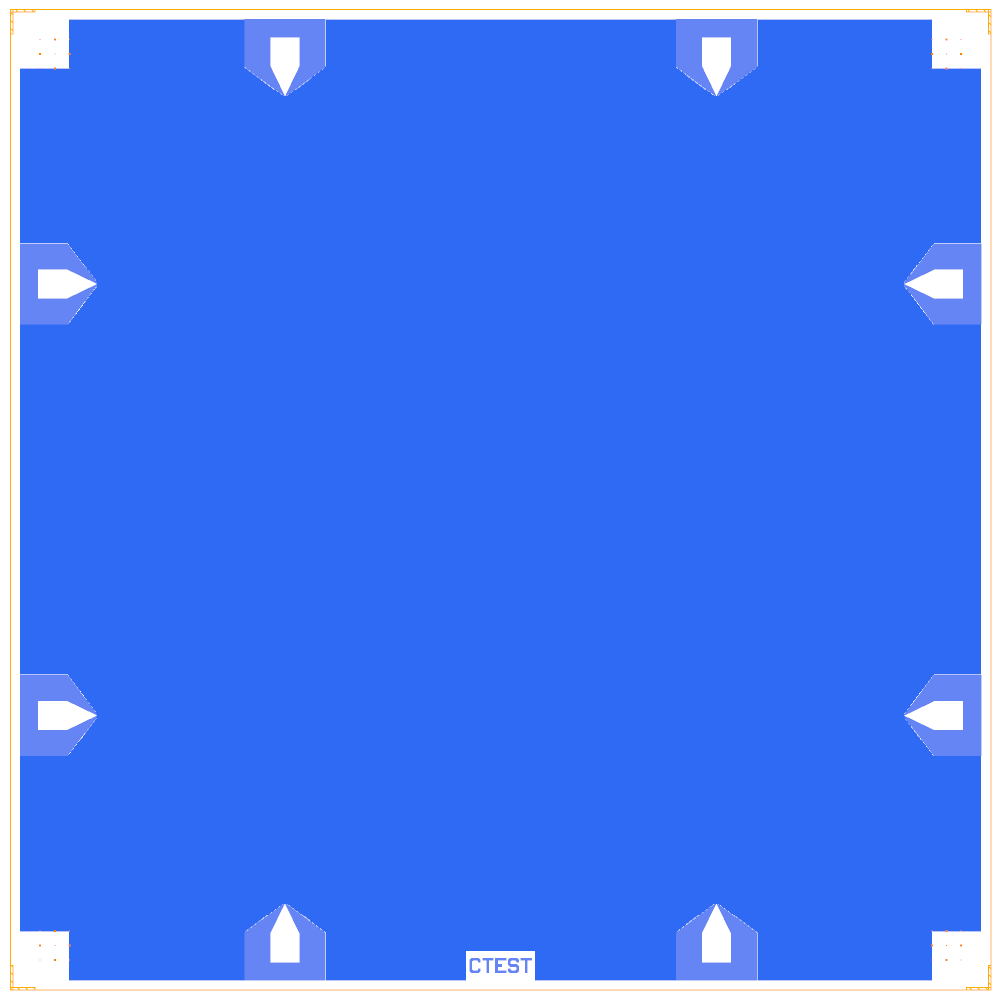

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout. The SMA8 launchers belong to the chip (the sample holder), not to the instances, so the pad count stays 0.

WindowsPath('build/snapshots/airbridge_crossings/1_die.png')

In [5]:
pads = {1: "PL-1-IN", 2: "PL-2-IN", 3: "PL-4-IN", 4: "PL-4-OUT", 5: "PL-2-OUT", 6: "PL-1-OUT", 7: "PL-3-OUT", 8: "PL-3-IN"}
d = Designer("airbridge_crossings", box=(0, 0, 10000, 10000), launchers={"type": "SMA8", "assign": pads},
             chip={"name_chip": "CTest", "with_grid": True}, live=LIVE)
CHIP = dict(box=(-100, -100, 10100, 10100), size=(1000, 1000), width=420)   # the v1's full-chip picture
layout_step(d, STEPS / "1_die.png", **CHIP,
            note="The SMA8 launchers belong to the chip (the sample holder), not to the instances, so the "
                 "pad count stays 0.")

## Design 2 · Bond pads: the launchers and the pad rule

**PDK rule:** a launcher's outer etch edge sits `frame.pad_edge` (100 µm) from the die edge. For SMA8 (RF launcher:
300 µm taper + 300 µm pad + 180 µm frame gap) the Designer sets `launcher_indent` = 100 + 300 + 300 + 180 =
**880 µm** (KQC: 800 µm). Every line below starts at a launcher port or at a waypoint taken from one, so the 80 µm
shift needs no other change.

The launchers came with the die (Design 1): nothing is added here. The table measures them, the picture zooms on PL-1-IN.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| chip.PL-1-IN | launcher port | n | port 880 µm in (indent from the rule) | ✓ |
| chip.PL-2-IN | launcher port | n | port 880 µm in (indent from the rule) | ✓ |
| chip.PL-4-IN | launcher port | e | port 880 µm in (indent from the rule) | ✓ |
| chip.PL-4-OUT | launcher port | e | port 880 µm in (indent from the rule) | ✓ |
| chip.PL-2-OUT | launcher port | s | port 880 µm in (indent from the rule) | ✓ |
| chip.PL-1-OUT | launcher port | s | port 880 µm in (indent from the rule) | ✓ |
| chip.PL-3-OUT | launcher port | w | port 880 µm in (indent from the rule) | ✓ |
| chip.PL-3-IN | launcher port | w | port 880 µm in (indent from the rule) | ✓ |

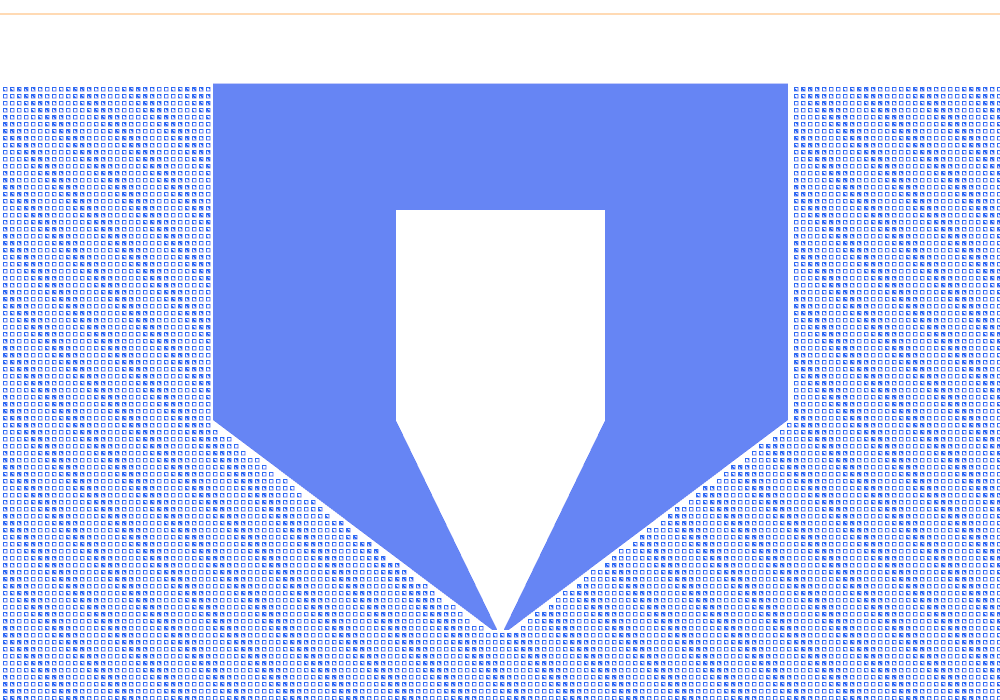

In [6]:
display(Markdown(pads_md(d)))
x, y = port_xy(d, "chip.PL-1-IN")
snap(d, STEPS / "2_launcher.png", box=(x - 400, y - 100, x + 400, 10000 + 20), size=(1000, 700), width=420);

## Design 3 · Test structures: the mechanical airbridge array

In the middle of the chip, KQC's mechanical test: 19 bridge lengths × 8 widths × 4 distances = 608 short straight
CPWs (`WaveguideCoplanarStraight`, KQC's length 2 · 5 · (distance + width) + 4 µm, on KQC's grid (3600, 9650) +
(400 j, −121 i − 2350 k)), with five default airbridges (`AirbridgeRectangular`) across every second row inside
1000 < y < 9000 µm: 1280 bridges. They join nothing (each bridge spans its stub, both pads on the ground), so the
pictures show whether the bridges are where KQC puts them. This cell places 1888 instances, so it takes a while; the
first picture is the whole chip, the second zooms on the first three rows of the second block (k = 1), where the
bridged rows alternate with plain ones.

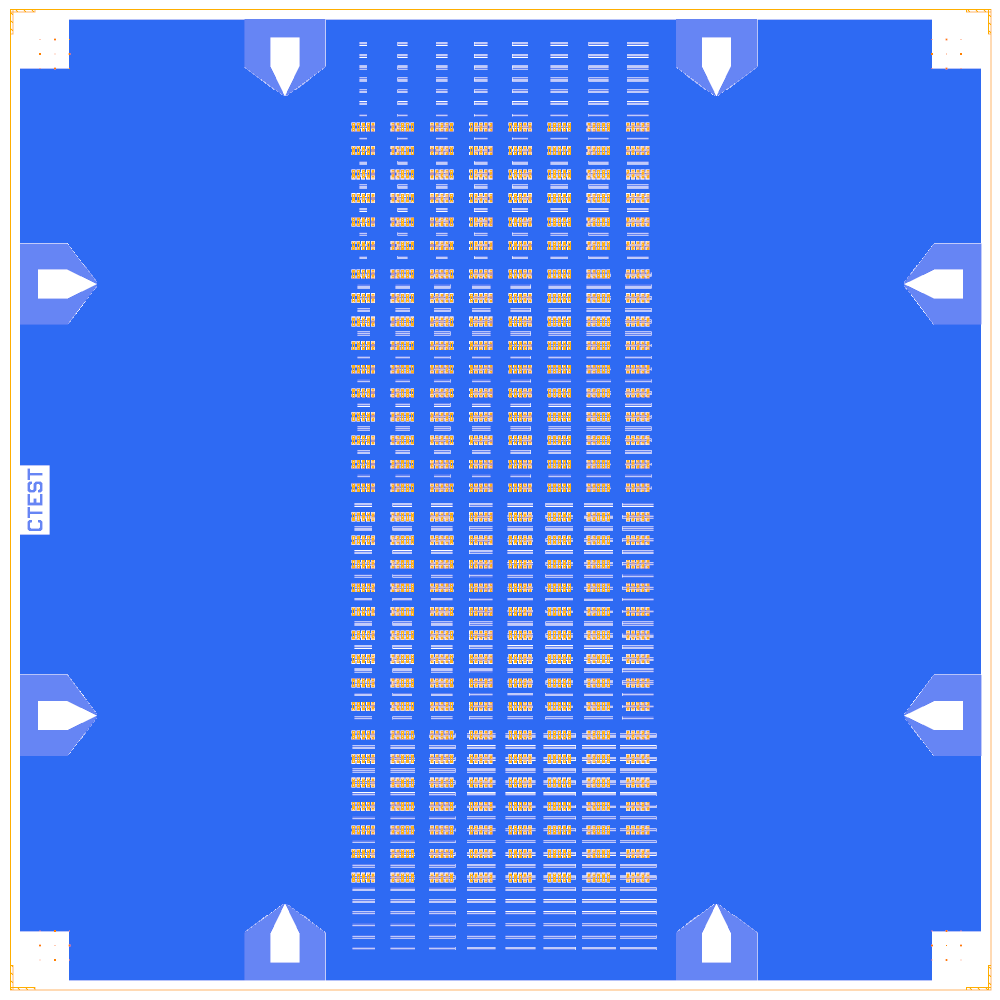

**On the chip so far:** 0 pads · 0 qubits · 1888 other components · 0 routes · 0 declared couplings. **This step added** 1888 component(s) `M0_0_0`, `M0_0_1`, `AB0_0_1_0`, `AB0_0_1_1`, `AB0_0_1_2`, `AB0_0_1_3`, `AB0_0_1_4`, `M0_0_2` … (+1880).

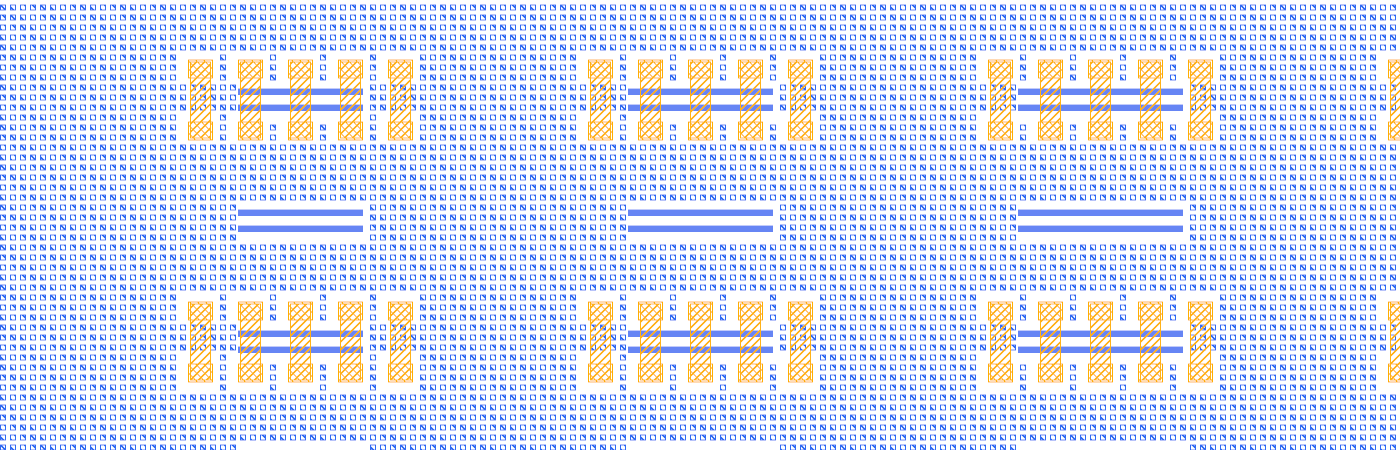

608 CPWs, 1280 bridges


In [7]:
crossings, wiggle, b_number = 10, 250, 5            # KQC defaults (crossings = pairs of crossings)
with d.batch():
    # mechanical test array: CPW length from width and distance; bridges on every second row inside 1000 < y < 9000
    n_bridges = 0
    for i, length in enumerate(range(22, 60, 2)):
        for j, width in enumerate(range(5, 20, 2)):
            for k, distance in enumerate(range(2, 22, 5)):
                x, y = 3600 + 400 * j, 9650 - 121 * i - 2350 * k
                wg_len = 2 * b_number * (distance + width) + 4
                d.add(f"M{i}_{j}_{k}", "WaveguideCoplanarStraight", at=(x - wg_len / 2, y), l=wg_len)
                if (i + k) % 2 == 1 and 1000 < y < 9000:
                    for n in range(b_number):
                        d.add(f"AB{i}_{j}_{k}_{n}", "AirbridgeRectangular", at=(x + 50 * (n - (b_number - 1) / 2), y))
                        n_bridges += 1
layout_step(d, STEPS / "s3_array.png", **CHIP)
snap(d, STEPS / "s3_array_rows.png", box=(3300, 6950, 4700, 7400), size=(1400, 450), width=640)
print(sum(1 for n in d.data["instances"] if n.startswith("M")), "CPWs,", n_bridges, "bridges")

## Design 4 · Routing: the four lines

PL-1 and PL-2 run straight between their launchers; PL-3 weaves across PL-1 ten times each way, every crossing a waypoint with `airbridge=True` (KQC's `Node(..., AirbridgeConnection)`); PL-4 weaves the same way next to PL-2 without crossing. Every line starts at a launcher port or at a
waypoint taken from one (`port_xy`), so the launchers' PDK indent carries over. The first picture is the whole chip,
the second zooms on PL-4's weave beside PL-2 (the crossings of PL-3 are in Fab 2).

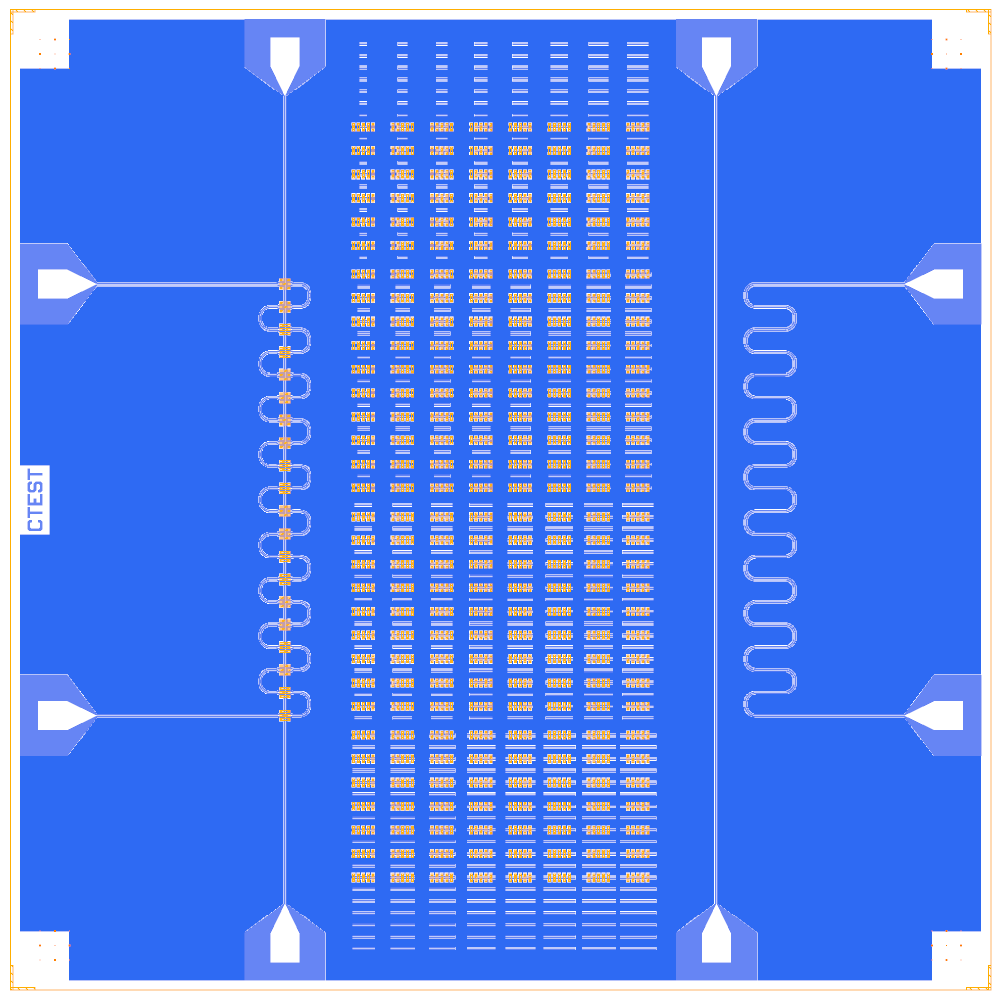

**On the chip so far:** 0 pads · 0 qubits · 1888 other components · 4 routes · 0 declared couplings. **This step added** 4 route(s) `PL1`, `PL2`, `PL3`, `PL4`.

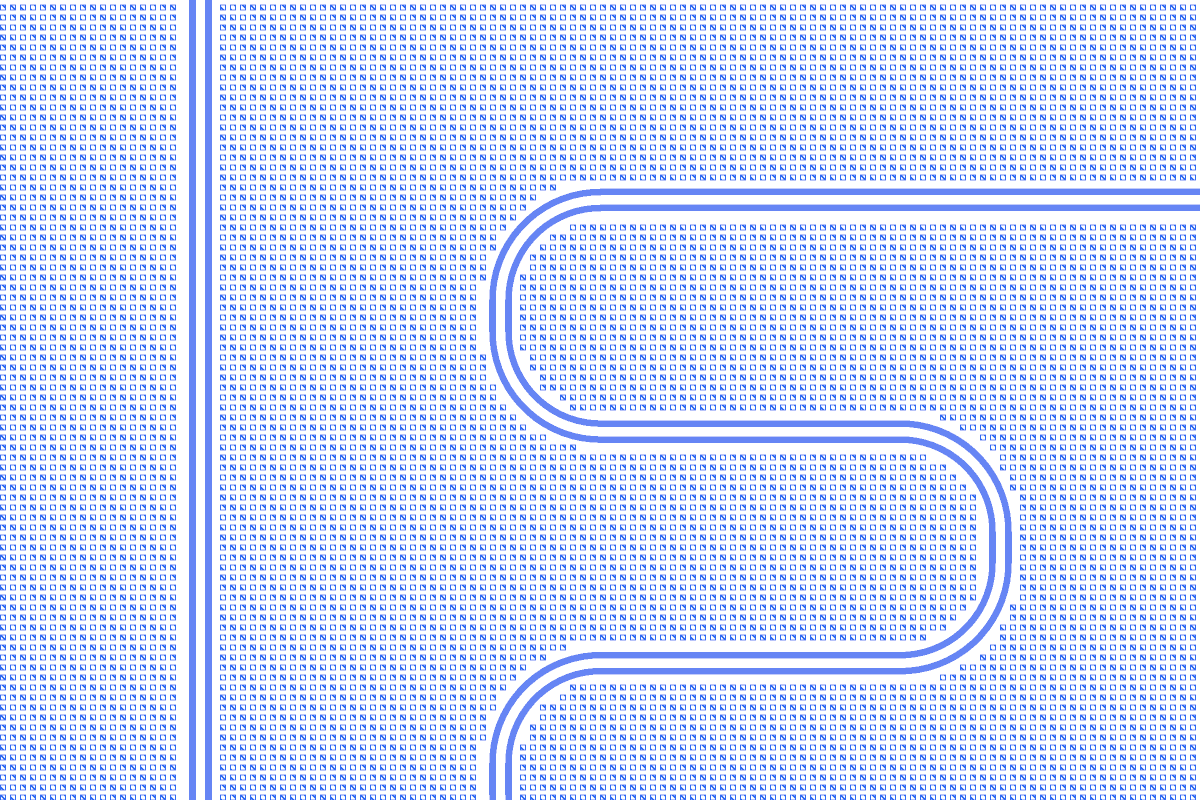

{'PL1': 8240.0, 'PL2': 8240.0, 'PL3': 16109.04, 'PL4': 15009.03}


In [8]:
W = d.waypoint
x_pl1, _ = port_xy(d, "chip.PL-1-IN")
x_pl2, _ = port_xy(d, "chip.PL-2-IN")
_, y_in = port_xy(d, "chip.PL-3-IN")
_, y_out = port_xy(d, "chip.PL-3-OUT")
step = (y_in - y_out) / (crossings - 0.5) / 2
with d.batch():
    d.route("PL1", "chip.PL-1-IN", "chip.PL-1-OUT")      # straight, x = 2800
    d.route("PL2", "chip.PL-2-IN", "chip.PL-2-OUT")      # straight, x = 7200
    nodes, y = [], y_in                                  # PL-3 weaves across PL-1 on airbridges
    for _ in range(crossings):
        nodes += [(x_pl1 - wiggle, y), W((x_pl1, y), airbridge=True), (x_pl1 + wiggle, y)]
        y -= step
        nodes += [(x_pl1 + wiggle, y), W((x_pl1, y), airbridge=True), (x_pl1 - wiggle, y)]
        y -= step
    d.route("PL3", "chip.PL-3-IN", "chip.PL-3-OUT", nodes=nodes)
    nodes, y, xr = [], y_in, x_pl2 + 2 * wiggle + 50     # PL-4: the same weave, no crossing
    for _ in range(crossings):
        nodes += [(xr + wiggle, y), (xr - wiggle, y)]
        y -= step
        nodes += [(xr - wiggle, y), (xr + wiggle, y)]
        y -= step
    d.route("PL4", "chip.PL-4-IN", "chip.PL-4-OUT", nodes=nodes)
layout_step(d, STEPS / "4_routes.png", **CHIP)
snap(d, STEPS / "s4_pl4.png", box=(7000, 6600, 8200, 7400), size=(1200, 800), width=480)
print({k: round(v, 2) for k, v in d.result.route_lengths().items()})

## Design 5 · The whole chip: centring, save

No sim groups: through lines only (the v1 rebuild has none; Simulate says what one would take). `center_in_die` checks that the content sits centred in the die and shifts it if it is more
than 50 µm off. Then the design is saved with `save_design`, which compares it with the file it replaces (the
previous run's): the array came before the lines here, so `save_design` writes the previous file's key order back,
and it should say *same design*.

In [9]:
print("centring shift (µm):", center_in_die(d))
rebuild(d)
DESIGN, same = save_design(d, OUT / "airbridge_crossings.json")
display(Markdown(same))
print(d, "→", DESIGN)

centring shift (µm): (0.0, 0.0)


**Same design as before:** `examples/designs/kqc/test_chips/airbridge_crossings.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer airbridge_crossings: 1888 instances, 4 routes, live=False> → examples\designs\kqc\test_chips\airbridge_crossings.json


# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

The DRC reports three kinds of issue. **Errors** (overlaps, crossings without a bridge, unconnected ends, metal
outside the die) make the build unfit for fab. **Warnings** are connectivity or geometry notes to read. **PDK
design warnings** flag values outside the PDK margins (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): flagged,
never enforced — the rebuild keeps the source's choices. `pdk_report` adds the cheese source, the centring
and the junction types.

**Expected here (from the v1 run):** 0 errors, 0 PDK design warnings and 7052 warnings, all on the mechanical array: 2560 `dangling_port` (both ports of each of the 1280 test bridges, which sit across a short CPW stub with both pads on the ground plane and join nothing) and 4492 `overlap` (bounding-box overlaps of those bridges with their own stub, the neighbouring rows' stubs and the bridges two rows away; KQC places them so). The routes are clean: PL-3 crosses PL-1 only on its 20 airbridge crossings, which the `crossing` rule accepts. `pdk_report` gives KQC's grid ("the original design's own"), the content 36 µm off in y and no junctions.

In [ ]:
display(Markdown(drc_md(d.drc())))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

`d.lom()` turns the layout into a lumped circuit from the components' LOM models: launchers are 50 Ω ports, a route
between two ports is one conductor (a through line), a route to a shorted end is a λ/4 resonator.

In [ ]:
lb = d.lom()
summary = lom_summary(lb)
print(summary)
print("ports whose node is not in the circuit:",
      sum(1 for p, n in lb.port_map.items() if not n.startswith("control:") and n not in lb.model.nodes))
print(netlist_md(lb, max_notes=4).split("**Unconnected ports:**")[0])

# LOM: nothing to simulate

None: no junctions or resonators (four 50 Ω through lines). What the chip measures, the transmission across the crossings and the PL-1 ↔ PL-3 crosstalk, needs a driven FEM solve (Simulate).

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: nothing to export

The design has no sim groups, so the export below writes no FEM job and the switches at the top change nothing here.
What the chip measures, the transmission across the crossings and the PL-1 ↔ PL-3 crosstalk, is a driven S-parameter problem: `sim_tools` exports `hfss_driven` jobs, but for a sim group, and adding
one would change the design file (a new revision of the chip, not this rebuild).

In [ ]:
jobs = export_sims(DESIGN)                       # one job per sim group: this design has none
display(Markdown(jobs_md(jobs) if jobs else "No sim groups: no FEM job."))

# Results: the layout against the source

The chip has no simulated quantity to hold against a model, so its *compare* step is the XOR with KQC's own build of
the same chip.

## Results 1 · XOR with KQC

**Reference: XOR with the source.** KQC's chip built stand-alone, XOR-ed layer by layer with this build (the union
of both layer sets; `refpoints`, `ports` and the `instance_names` label layer are annotation and are skipped). The
reference gets `name_brand="QC"`; with KQC's default "IQM" the frame text adds its area (last line). The column
"> 1 nm" is the XOR shrunk by one database unit. **The rebuild is expected to differ** by design: the frame (KQC's
ChipFrame vs the Quantcore die frame), the ground grid (KQC's stand-alone build has none) and the launchers with their lines' first legs (80 µm deeper here). A reference, not a pass/fail check.

In [ ]:
import klayout.db as kdb
from kqcircuits.chips.airbridge_crossings import AirbridgeCrossings as KqcChip


def xor_vs_kqc(**ref_params):
    ref = pya.Layout()
    ref_top = ref.create_cell("ref")
    ref_top.insert(pya.DCellInstArray(KqcChip.create(ref, **ref_params).cell_index(), pya.DTrans()))
    ly = kdb.Layout()
    ly.read(str(d.out))
    top = ly.top_cell()
    mine = {ly.get_info(i).name: i for i in ly.layer_indexes()}
    theirs = {ref.get_info(i).name: i for i in ref.layer_indexes()}
    rows = []
    for name in sorted(set(mine) | set(theirs)):
        if not name or name in ("refpoints", "instance_names", "ports"):
            continue
        a = kdb.Region(ref_top.begin_shapes_rec(theirs[name])).merged() if name in theirs else kdb.Region()
        b = kdb.Region(top.begin_shapes_rec(mine[name])).merged() if name in mine else kdb.Region()
        if a.is_empty() and b.is_empty():
            continue
        x = a ^ b
        rows.append((name, x.area() * ref.dbu ** 2, x.sized(-1).area() * ref.dbu ** 2,
                     None if x.is_empty() else x.bbox().to_dtype(ref.dbu)))
    return rows


rows = xor_vs_kqc(name_brand="QC")
table = ["| layer | XOR area (µm²) | > 1 nm (µm²) | where |", "|---|---|---|---|"]
table += [f"| {n} | {x:.3g} | {y:.3g} | {w or ''} |" for n, x, y, w in rows]
total, real = sum(r[1] for r in rows), sum(r[2] for r in rows)
iqm = sum(r[1] for r in xor_vs_kqc())
display(Markdown("\n".join(table) + f"\n\n**Total XOR area: {total:.3g} µm²** ({real:.3g} µm² wider than 1 nm). "
                 f"Against KQC's default brand text \"IQM\": {iqm:.3g} µm²."))

**From the v1 run:** the XOR (1.5 × 10⁸ µm²) is all from the expected differences: the qcc frame layers (the boundary layer alone 1 × 10⁸ µm²), the ground grid (2.0 × 10⁷ µm²) and its avoidance, KQC's frame (EBL, dicing and airbridge-marker layers) and the launcher shift (waveguide path 6.4 × 10³ µm²). The 1340 bridges and the 608 stubs add nothing on the airbridge layers beyond KQC's frame markers (the same 2.81 / 5.4 × 10⁵ µm² as on every test chip here).

## Results 2 · Feedback: none

There is no target to iterate towards: the lines follow KQC's paths and parameters, and a variant (another crossing count, other bridge spans) is a
new layout, checked again by the DRC and the XOR above.

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

**The design file.** `airbridge_crossings.json` (saved in Design 5) is the whole design: `qcc build
examples/designs/kqc/test_chips/airbridge_crossings.json` rebuilds `build/airbridge_crossings.oas` + its sidecar, and the KLayout plugin,
`qcc watch` and the dashboard read it.

**The fab mask.** `export_fab` writes only the PDK fab layers: base etch 1/0 (with the cheese), the filled 3/0 keep-out (CPW footprint + 10 µm, components' etch bbox + 24 µm; 3/0 also holds every cheese
hole), airbridges 300/0 (pads) and 301/0 (bridges),
and the frame (100/0, 1000/0, 1001/0). The cheese source is `build`: KQC's grid drawn in the build (`with_grid=True`) stands, and no PDK band is added. In the v1 run: 1/0 807 806 polygons, 3/0 766 969, airbridges 2680 pads (300/0) and 1340 bridges (301/0: the 1280 test bridges plus 3 per crossing); cheese source `build`, 806 561 holes. Corner rounding (fab only) is skipped unless `FULL_FAB`;
`qcc mask examples/designs/kqc/test_chips/airbridge_crossings.json` writes the complete file.

In [ ]:
display(Markdown(fab_layers_md(d, cheese=True, rounding=FULL_FAB)))

## Fab 2 · Snapshots

The snapshots of the source notebook (full chip and its zooms; the die frame's south-west corner, dicing L on
1000/0 and the 3 × 3 alignment grid on 1001/0) and one PL-3 crossing over PL-1 in the **fab view** (the mask from Fab 1: 1/0
and 3/0 with the grid holes). KQC's grid fills the ground as one tone at full-chip scale; the chip boundary 100/0
is drawn as an outline.

In [ ]:
show_snapshot(d, OUT / "airbridge_crossings.png", box=(-100, -100, 10100, 10100))
show_snapshot(d, OUT / "airbridge_crossings_crossing.png", box=(2450, 6650, 3150, 7350), width=420)
show_snapshot(d, OUT / "airbridge_crossings_array.png", box=(3300, 7050, 6600, 7550), size=(1600, 250), width=640)
show_snapshot(d, OUT / "airbridge_crossings_bridge.png", box=(3530, 7180, 3670, 7420), size=(600, 1000), width=180)
show_snapshot(d, OUT / "airbridge_crossings_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300)
snap_file(Path("build") / "airbridge_crossings_fab.oas", OUT / "airbridge_crossings_fab.png", box=(2700, 6900, 2900, 7100), size=(1200, 1200), width=420);

## Summary

| | |
|---|---|
| **matches the source** | KQC's cells with their parameters, positions and paths; KQC's whole-area ground grid |
| **differs (PDK)** | the Quantcore die frame instead of KQC's ChipFrame; the launchers 80 µm further in (outer etch 100 µm, `frame.pad_edge`) with the lines' first legs; sapphire |
| **PDK design warnings** | as listed in Check 1 |
| **FEM** | no sim groups, no jobs |
| layout | built in five segments (die and launchers, the launcher check, the mechanical array, the four lines, the whole chip); the saved JSON is the v1 notebook's |
| feedback | none: through lines, no simulated quantity; the XOR with KQC is the compare step (Results 1) |
| open | a driven S-parameter job of one crossing would need a sim group (a new design revision) |